#### Table of contents
- 1. Missing Data Taxonomy (MCAR, MAR, MNAR)
- 2. Imputation Strategies (KNN, Iterative, Rolling)
- 3. Outlier Handling via Winsorization & Clipping
- 4. Duplicate Detection & Entity Resolution Basics


In [4]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from scipy.stats import mstats

print("Global imports : successful")

Global imports : successful


In [5]:
# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print(
    "Global libraries for missing data analysis & imputation loaded"
    " successfully."
)

Global libraries for missing data analysis & imputation loaded successfully.


#### 1. Missing Data Taxonomy (MCAR, MAR, MNAR)

In [6]:
np.random.seed(42)
df_tax = pd.DataFrame({
    'age': np.random.randint(20, 60, 100),
    'income': np.random.normal(50000, 15000, 100)
})
# print("Initial DataFrame:\n",df_tax.head())
# MAR (Missing At Random) simulation
df_tax.loc[df_tax['age'] < 30, 'income'] = np.nan
# print("DataFrame after introducing missing values:\n", df_tax.head())

# indentify missing values
print("Missing values in each column:\n", df_tax.isnull().sum())

# Visualization: Missing data matrix / heatmap pattern
# plt.figure(figsize=(7, 4))
# sns.heatmap(df_tax.isnull(), cbar=False, cmap='viridis')
# plt.title('Missingness Heatmap Pattern (MAR Simulation)')
# plt.show()

Missing values in each column:
 age        0
income    28
dtype: int64


#### Imputation Strategies (KNN, Iterative, Rolling)

#### 1.Math Formula
For KNN imputation, the missing value $x_{i,j}$ is imputed via distance-weighted average of $k$ nearest rows $\mathcal{N}_i$ based on feature distance metric $d$:
$$\hat{x}_{i,j} = \frac{\sum_{k \in \mathcal{N}_i} w_k x_{k,j}}{\sum_{k \in \mathcal{N}_i} w_k}$$

#### 2.  Notation Pronunciation
- $\mathcal{N}_i$: "Neighborhood set of row i"
- $w_k$: "Distance weight for neighbor k"
- `KNNImputer`: "K-Nearest Neighbors imputer"

DataFrame after KNN imputation:
    feature_1  feature_2
0        1.0        2.0
1        2.0        4.0
2        1.5        3.0
3        4.0        7.0
4        5.0       10.0


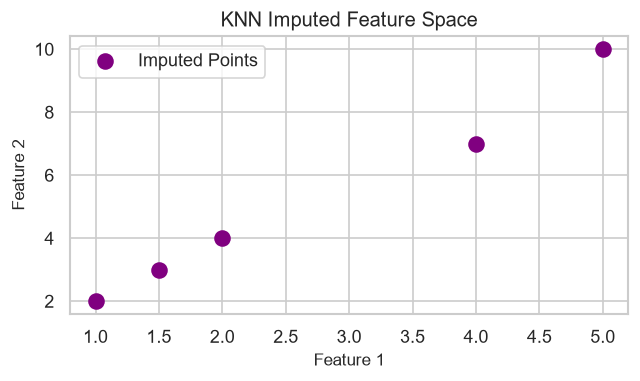

In [7]:
df_imp = pd.DataFrame({
    'feature_1': [1.0, 2.0, np.nan, 4.0, 5.0],
    'feature_2': [2.0, 4.0, 3.0, np.nan, 10.0]
})
imputer = KNNImputer(n_neighbors=2) # n_neighbors default is 5
df_imputed = pd.DataFrame(imputer.fit_transform(df_imp), columns=df_imp.columns)
print("DataFrame after KNN imputation:\n", df_imputed)

# visualization
plt.figure(figsize=(6, 3))
plt.scatter(df_imputed['feature_1'], df_imputed['feature_2'], color='purple', s=80, label='Imputed Points')
plt.title('KNN Imputed Feature Space')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.legend()
plt.show()


#### 3. Outlier Handling via Winsorization & Clipping

In [8]:
data_outliers = [10, 12, 14, 15, 13, 11, 12, 100, -50] # ouliers are 100 and -50
# sorted data for reference [-50, 10, 11, 12, 12, 13, 14, 15, 100]
# convert to a numpy array for further processing
arr_outliers = np.array(data_outliers)
# let us winsorize the outliers
winsorized_data = mstats.winsorize(arr_outliers, limits=[0.12, 0.12])
print("Original:", data_outliers)
print("Winsorized:", winsorized_data)

Original: [10, 12, 14, 15, 13, 11, 12, 100, -50]
Winsorized: [10 12 14 15 13 11 12 15 10]


####  4. Duplicate Detection & Entity Resolution Basics

In [9]:
df_dup = pd.DataFrame({
    'customer_id': [101, 102, 101, 103],
    'name': ['Alice', 'Bob', 'Alice', 'Charlie'],
    'purchase_amt': [250, 150, 250, 300]
})
print("Original DataFrame with duplicates:\n", df_dup)
print("_" * 50)
# duplicate mask
duplicate_mask = df_dup.duplicated()
print("Duplicate mask:\n", duplicate_mask)
print("_" * 50)
# remove duplicates
df_no_duplicates = df_dup.drop_duplicates()
print("DataFrame after removing duplicates:\n", df_no_duplicates)
print("_" * 50)

Original DataFrame with duplicates:
    customer_id     name  purchase_amt
0          101    Alice           250
1          102      Bob           150
2          101    Alice           250
3          103  Charlie           300
__________________________________________________
Duplicate mask:
 0    False
1    False
2     True
3    False
dtype: bool
__________________________________________________
DataFrame after removing duplicates:
    customer_id     name  purchase_amt
0          101    Alice           250
1          102      Bob           150
3          103  Charlie           300
__________________________________________________


---
## Summary Table

| Missingness / Data Issue | Underlying Mechanism | Recommended Treatment Strategy | Primary Objective |
| :--- | :--- | :--- | :--- |
| **MCAR** | Missing completely at random | Listwise deletion or any imputation | Unbiased estimates without structural risk |
| **MAR & MNAR** | Missing dependent on observed/unobserved data | KNN Imputation, MICE, or explicit indicator flags | Preserving multivariate distribution |
| **Extreme Outliers** | Skewed measurement or data corruption | Winsorization & percentile clipping | Robust parameter estimation without sample loss |
| **Entity Duplicates** | Typos, inconsistent formatting, system merges | Exact deduplication & string similarity matching | Ensuring primary key uniqueness & data integrity |